<h2 style="break-before: page; page-break-before: always;">
Q2.1
</h2>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.utils import resample
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import confusion_matrix

SEED = 123123

In [2]:
def split_data(X, y):
    """Split data into train, validation, and test."""

    # 80/20 split: train vs. remaining
    X_train, X_rest, y_train, y_rest = train_test_split(
        X, y, train_size=0.8, random_state=SEED
    )

    # 50/50 split for validation and test
    X_val, X_test, y_val, y_test = train_test_split(
        X_rest, y_rest, train_size=0.5, random_state=SEED
    )
    return X_train, X_val, X_test, y_train, y_val, y_test


def make_models():
    # Initialize models with default settings
    return {
        "KNN": KNeighborsClassifier(),
        "Decision Tree": DecisionTreeClassifier(random_state=SEED),
        "Linear Regression": LinearRegression(),
        "Logistic Regression": LogisticRegression(),
    }


def predict_labels(model, X):
    predictions = model.predict(X)
    # Convert linear regression output to binary labels
    if isinstance(model, LinearRegression):
        predictions = (predictions >= 0.5).astype(int)
    return predictions


def metrics(y_true, y_pred):
    # Positive class is class 1.
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    denom = precision + recall
    f1 = 2 * precision * recall / denom if denom else 0.0

    return {
        "cm": cm,
        "accuracy": (tn + tp) / cm.sum(),
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "class0_correct": tn / (tn + fp) if tn + fp else 0.0,
        "class1_correct": recall,
    }


def print_metrics(name, m):
    print(f"\n{name}")
    print(m["cm"])
    print(f"  Accuracy: {m['accuracy']:.4f}")
    print(f"  Positive-class precision: {m['precision']:.4f}")
    print(f"  Positive-class recall: {m['recall']:.4f}")
    print(f"  Positive-class F1: {m['f1']:.4f}")


def fit_and_evaluate(models, X_fit, y_fit, X_eval, y_eval):
    # Fit models and evaluate
    results = {}
    for name, model in models.items():
        model.fit(X_fit, y_fit)
        results[name] = metrics(y_eval, predict_labels(model, X_eval))
    return results

In [3]:
# Load data
data = np.loadtxt('A2Q2-troublesome-data.csv', delimiter=',', skiprows=1)

X = data[:, 1:3]
Y = data[:, 3].astype(int)

# Q2.1 Split the data into training, validation, and test sets
X_train, X_val, X_test, y_train, y_val, y_test = split_data(X, Y)

# Class counts and groups, reused in Q2.8 and Q2.9
class_counts = np.bincount(y_train, minlength=2)
majority_class = int(np.argmax(class_counts))
minority_class = 1 - majority_class
n_major = class_counts[majority_class]
n_minor = class_counts[minority_class]
X_minor = X_train[y_train == minority_class]
y_minor = y_train[y_train == minority_class]
X_major = X_train[y_train == majority_class]
y_major = y_train[y_train == majority_class]

print(f"Train: {len(X_train)}, Validation: {len(X_val)}, Test: {len(X_test)}")

Train: 8000, Validation: 1000, Test: 1000


<h2 style="break-before: page; page-break-before: always;">
Q2.2
</h2>

In [4]:
# Q2.2 Fit each model on the training split and evaluate on the validation split
baseline = fit_and_evaluate(make_models(), X_train, y_train, X_val, y_val)
for name, m in baseline.items():
    print(f"{name} validation accuracy: {m['accuracy']:.4f}")

KNN validation accuracy: 0.9930
Decision Tree validation accuracy: 0.9880
Linear Regression validation accuracy: 0.9880
Logistic Regression validation accuracy: 0.9920


<h2 style="break-before: page; page-break-before: always;">
Q2.4
</h2>

Number of classes: 2
Class counts (all): [9900  100]
Class counts (train): [7922   78]
Class counts (validation): [988  12]
Class counts (test): [990  10]
Fraction of class 1 overall: 0.0100


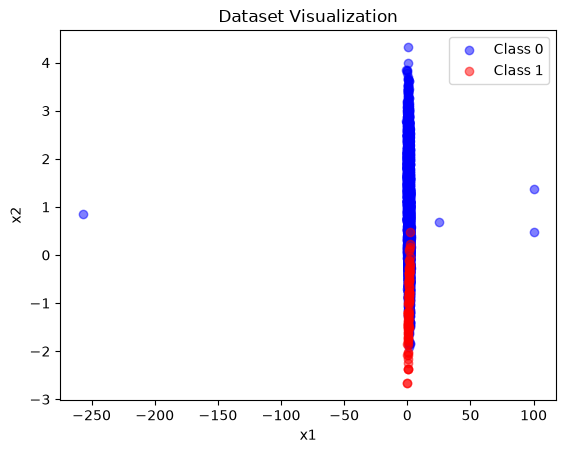

In [5]:
# Q2.4 Report class counts and plot the imbalance.
print(f"Number of classes: {len(np.unique(Y))}")
for split_name, labels in [("all", Y), ("train", y_train),
                           ("validation", y_val), ("test", y_test)]:
    print(f"Class counts ({split_name}): {np.bincount(labels, minlength=2)}")
print(f"Fraction of class 1 overall: {Y.mean():.4f}")

plt.figure()
plt.scatter(X[Y == 0, 0], X[Y == 0, 1], color='blue', label='Class 0', alpha=0.5)
plt.scatter(X[Y == 1, 0], X[Y == 1, 1], color='red', label='Class 1', alpha=0.5)
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('Dataset Visualization')
plt.legend()
plt.savefig('q2_4_scatter.png', dpi=150)
plt.show()

<h2 style="break-before: page; page-break-before: always;">
Q2.5
</h2>

In [6]:
# Q2.5 Per class accuracy and confusion matrix
for name, m in baseline.items():
    print(f"\n{name} confusion matrix:")
    print(m["cm"])
    print(f"  Class 0 correct: {m['class0_correct']:.4f}")
    print(f"  Class 1 correct: {m['class1_correct']:.4f}")


KNN confusion matrix:
[[986   2]
 [  5   7]]
  Class 0 correct: 0.9980
  Class 1 correct: 0.5833

Decision Tree confusion matrix:
[[981   7]
 [  5   7]]
  Class 0 correct: 0.9929
  Class 1 correct: 0.5833

Linear Regression confusion matrix:
[[988   0]
 [ 12   0]]
  Class 0 correct: 1.0000
  Class 1 correct: 0.0000

Logistic Regression confusion matrix:
[[987   1]
 [  7   5]]
  Class 0 correct: 0.9990
  Class 1 correct: 0.4167


<h2 style="break-before: page; page-break-before: always;">
Q2.7
</h2>

In [7]:
# Q2.7 Report the positive-class F1 score for each of the four models.
for name, m in baseline.items():
    print(f"{name} positive-class F1 score: {m['f1']:.4f}")

KNN positive-class F1 score: 0.6667
Decision Tree positive-class F1 score: 0.5385
Linear Regression positive-class F1 score: 0.0000
Logistic Regression positive-class F1 score: 0.5556


<h2 style="break-before: page; page-break-before: always;">
Q2.8
</h2>

In [8]:
# Q2.8 Over-sample the training set, evaluate on validation
extra_X, extra_y = resample(
    X_minor, y_minor, replace=True,
    n_samples=n_major - n_minor, random_state=SEED,
)
X_over = np.vstack((X_train, extra_X))
y_over = np.concatenate((y_train, extra_y))

print(f"Training class counts before: {dict(enumerate(class_counts.tolist()))}; "
      f"after: {dict(enumerate(np.bincount(y_over).tolist()))}")
oversampled = fit_and_evaluate(make_models(), X_over, y_over, X_val, y_val)
for name, m in oversampled.items():
    print_metrics(name, m)

Training class counts before: {0: 7922, 1: 78}; after: {0: 7922, 1: 7922}

KNN
[[975  13]
 [  4   8]]
  Accuracy: 0.9830
  Positive-class precision: 0.3810
  Positive-class recall: 0.6667
  Positive-class F1: 0.4848

Decision Tree
[[983   5]
 [  5   7]]
  Accuracy: 0.9900
  Positive-class precision: 0.5833
  Positive-class recall: 0.5833
  Positive-class F1: 0.5833

Linear Regression
[[877 111]
 [  0  12]]
  Accuracy: 0.8890
  Positive-class precision: 0.0976
  Positive-class recall: 1.0000
  Positive-class F1: 0.1778

Logistic Regression
[[901  87]
 [  0  12]]
  Accuracy: 0.9130
  Positive-class precision: 0.1212
  Positive-class recall: 1.0000
  Positive-class F1: 0.2162


<h2 style="break-before: page; page-break-before: always;">
Q2.9
</h2>

In [9]:
# Q2.9 Under-sample the majority class and evaluate on the unchanged validation set
# Keep only as many majority examples as there are minority examples
keep_X, keep_y = resample(
    X_major, y_major, replace=False,
    n_samples=n_minor, random_state=SEED,
)
X_under = np.vstack((X_minor, keep_X))
y_under = np.concatenate((y_minor, keep_y))

print(f"Training class counts before: {dict(enumerate(class_counts.tolist()))}; "
      f"after: {dict(enumerate(np.bincount(y_under).tolist()))}")
undersampled = fit_and_evaluate(make_models(), X_under, y_under, X_val, y_val)
for name, m in undersampled.items():
    print_metrics(name, m)

# Compare original, over-sampled and under-sampled results
print("\n=== Q2.9 comparison (validation) ===")
print(f"{'Model':<21}{'Training set':<15}{'Acc':>7}{'Prec':>8}{'Rec':>8}{'F1':>8}")
for name in baseline:
    for label, res in [("original", baseline), ("over", oversampled),
                       ("under", undersampled)]:
        m = res[name]
        print(f"{name:<21}{label:<15}{m['accuracy']:>7.4f}{m['precision']:>8.4f}"
              f"{m['recall']:>8.4f}{m['f1']:>8.4f}")

Training class counts before: {0: 7922, 1: 78}; after: {0: 78, 1: 78}

KNN
[[883 105]
 [  0  12]]
  Accuracy: 0.8950
  Positive-class precision: 0.1026
  Positive-class recall: 1.0000
  Positive-class F1: 0.1860

Decision Tree
[[907  81]
 [  1  11]]
  Accuracy: 0.9180
  Positive-class precision: 0.1196
  Positive-class recall: 0.9167
  Positive-class F1: 0.2115

Linear Regression
[[878 110]
 [  0  12]]
  Accuracy: 0.8900
  Positive-class precision: 0.0984
  Positive-class recall: 1.0000
  Positive-class F1: 0.1791

Logistic Regression
[[908  80]
 [  0  12]]
  Accuracy: 0.9200
  Positive-class precision: 0.1304
  Positive-class recall: 1.0000
  Positive-class F1: 0.2308

=== Q2.9 comparison (validation) ===
Model                Training set       Acc    Prec     Rec      F1
KNN                  original        0.9930  0.7778  0.5833  0.6667
KNN                  over            0.9830  0.3810  0.6667  0.4848
KNN                  under           0.8950  0.1026  1.0000  0.1860
Decision Tre

<h2 style="break-before: page; page-break-before: always;">
Q2.10
</h2>

x1: min -257.000, median 1.001, max 100.000
  IQR-rule outliers: 72 (0.72%); class counts among them: [69  3]
x2: min -2.665, median 1.002, max 4.322
  IQR-rule outliers: 124 (1.24%); class counts among them: [78 46]


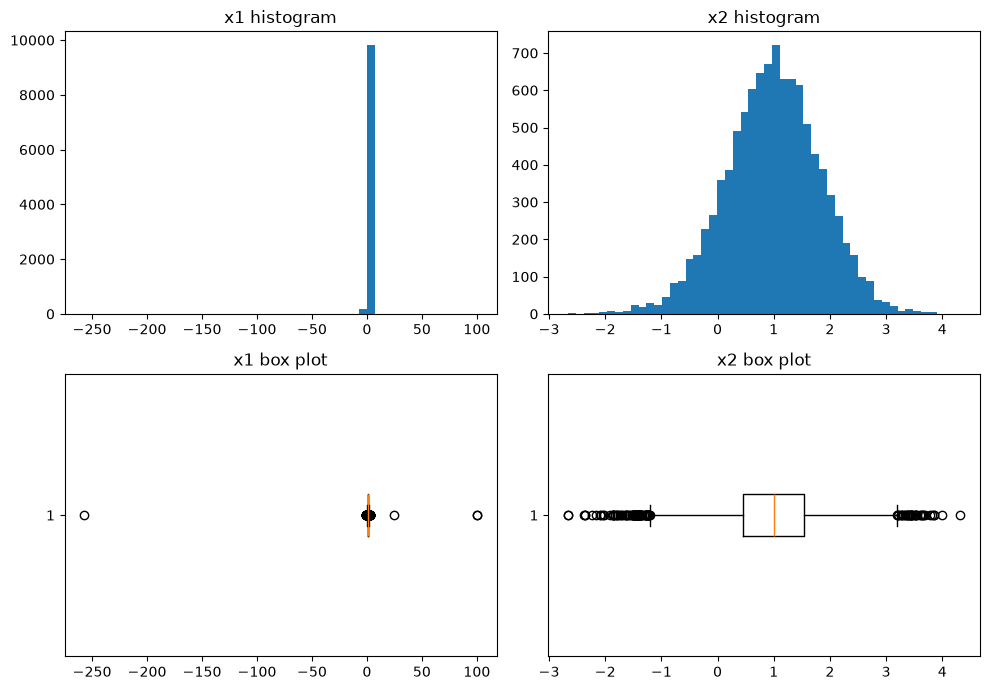

In [10]:
# Q2.10 Explore the dataset, and report on which features have outliers
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for j, feat in enumerate(["x1", "x2"]):
    col = X[:, j]
    axes[0, j].hist(col, bins=50)
    axes[0, j].set_title(f"{feat} histogram")
    axes[1, j].boxplot(col, orientation='horizontal')
    axes[1, j].set_title(f"{feat} box plot")

    # Count points outside 1.5 x IQR, and see which classes they belong to
    q1, q3 = np.percentile(col, [25, 75])
    iqr = q3 - q1
    is_outlier = (col < q1 - 1.5 * iqr) | (col > q3 + 1.5 * iqr)
    print(f"{feat}: min {col.min():.3f}, median {np.median(col):.3f}, "
          f"max {col.max():.3f}")
    print(f"  IQR-rule outliers: {is_outlier.sum()} ({is_outlier.mean():.2%}); "
          f"class counts among them: {np.bincount(Y[is_outlier], minlength=2)}")
fig.tight_layout()
fig.savefig('q2_10_outliers.png', dpi=150)
plt.show()

<h2 style="break-before: page; page-break-before: always;">
Q2.11
</h2>

In [11]:
# Q2.11 Using the original training set, train KNN models with k = 1, 3, 5
# and report their validation confusion matrices.
for k in [1, 3, 5]:
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    print_metrics(f"KNN (k={k})", metrics(y_val, knn.predict(X_val)))


KNN (k=1)
[[984   4]
 [  5   7]]
  Accuracy: 0.9910
  Positive-class precision: 0.6364
  Positive-class recall: 0.5833
  Positive-class F1: 0.6087

KNN (k=3)
[[985   3]
 [  5   7]]
  Accuracy: 0.9920
  Positive-class precision: 0.7000
  Positive-class recall: 0.5833
  Positive-class F1: 0.6364

KNN (k=5)
[[986   2]
 [  5   7]]
  Accuracy: 0.9930
  Positive-class precision: 0.7778
  Positive-class recall: 0.5833
  Positive-class F1: 0.6667


<h2 style="break-before: page; page-break-before: always;">
Q2.12
</h2>

In [12]:
#Q2.12 Decision trees, max_depth = 1, 2, 3, original training set

for depth in [1, 2, 3]:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
    tree.fit(X_train, y_train)
    m = metrics(y_val, tree.predict(X_val))
    print_metrics(f"Decision Tree (max_depth={depth})", m)


Decision Tree (max_depth=1)
[[984   4]
 [  5   7]]
  Accuracy: 0.9910
  Positive-class precision: 0.6364
  Positive-class recall: 0.5833
  Positive-class F1: 0.6087

Decision Tree (max_depth=2)
[[988   0]
 [  5   7]]
  Accuracy: 0.9950
  Positive-class precision: 1.0000
  Positive-class recall: 0.5833
  Positive-class F1: 0.7368

Decision Tree (max_depth=3)
[[988   0]
 [  5   7]]
  Accuracy: 0.9950
  Positive-class precision: 1.0000
  Positive-class recall: 0.5833
  Positive-class F1: 0.7368
